In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
)

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../data/PJME_hourly.csv")
df["Datetime"] = pd.to_datetime(df["Datetime"])

df.head()

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [5]:
df.info()
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  145366 non-null  datetime64[us]
 1   PJME_MW   145366 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.2 MB
                         Datetime        PJME_MW
count                      145366  145366.000000
mean   2010-04-18 03:25:25.999202   32080.222831
min           2002-01-01 01:00:00   14544.000000
25%           2006-02-23 14:15:00   27573.000000
50%           2010-04-18 04:30:00   31421.000000
75%           2014-06-10 18:45:00   35650.000000
max           2018-08-03 00:00:00   62009.000000
std                           NaN    6464.012166


In [6]:
print(df.isna().sum())
print("Début :", df["Datetime"].min(), "| Fin :", df["Datetime"].max())

Datetime    0
PJME_MW     0
dtype: int64
Début : 2002-01-01 01:00:00 | Fin : 2018-08-03 00:00:00


In [11]:
# combien d'observations par année??
print(df.groupby(df["Datetime"].dt.year).size())

Datetime
2002    8757
2003    8758
2004    8782
2005    8758
2006    8758
2007    8758
2008    8782
2009    8758
2010    8757
2011    8758
2012    8782
2013    8758
2014    8760
2015    8760
2016    8784
2017    8760
2018    5136
dtype: int64


In [12]:
# Écart entre deux timestamps consécutifs (après tri)
ecarts = df.sort_values("Datetime")["Datetime"].diff().value_counts().head()
print(ecarts)

Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
0 days 00:00:00         4
Name: count, dtype: int64


## Nettoyage

In [15]:
print("Lignes entièrement dupliquées :", df.duplicated().sum())
print("Timestamps dupliqués          :", df["Datetime"].duplicated().sum())


q1, q3 = df["PJME_MW"].quantile([0.25, 0.75])
iqr = q3 - q1
bas  = q1 - 1.5 * iqr
haut = q3 + 1.5 * iqr
print("Valeurs <= 0 :", (df["PJME_MW"] <= 0).sum())
print(f"Hors IQR [{bas:.0f}, {haut:.0f}] :", ((df["PJME_MW"] < bas) | (df["PJME_MW"] > haut)).sum())

Lignes entièrement dupliquées : 0
Timestamps dupliqués          : 4
Trié chronologiquement ?      : False
Valeurs <= 0 : 0
Hors IQR [15458, 47766] : 3455


In [16]:
print("Trié chronologiquement ?      :", df["Datetime"].is_monotonic_increasing)

Trié chronologiquement ?      : False


1) Doublons : dans ce type de dataset, ils viennent du passage à l'heure d'hiver
(la même heure apparaît 2 fois). On garde UN point par timestamp en faisant la moyenne.
groupby trie aussi par Datetime, ça règle déjà le tri.
2) Tri explicite
3) Valeurs aberrantes : les pics hauts (canicule, vague de froid) sont RÉELS,
on les garde. Seules les valeurs <= 0 sont impossibles, on les met à NaN.
4) Heures manquantes (passage à l'heure d'été) : on recrée une série horaire
complète puis on interpole.

In [18]:
df = df.groupby("Datetime", as_index=False)["PJME_MW"].mean()

df = df.sort_values("Datetime").reset_index(drop=True)

df.loc[df["PJME_MW"] <= 0, "PJME_MW"] = np.nan

s = df.set_index("Datetime")["PJME_MW"].asfreq("h")
print("Heures manquantes :", s.isna().sum())
s = s.interpolate(method="time")

print("Après nettoyage :", s.isna().sum(), "NaN | longueur :", len(s))

Heures manquantes : 30
Après nettoyage : 0 NaN | longueur : 145392


## Analyse exploratoire

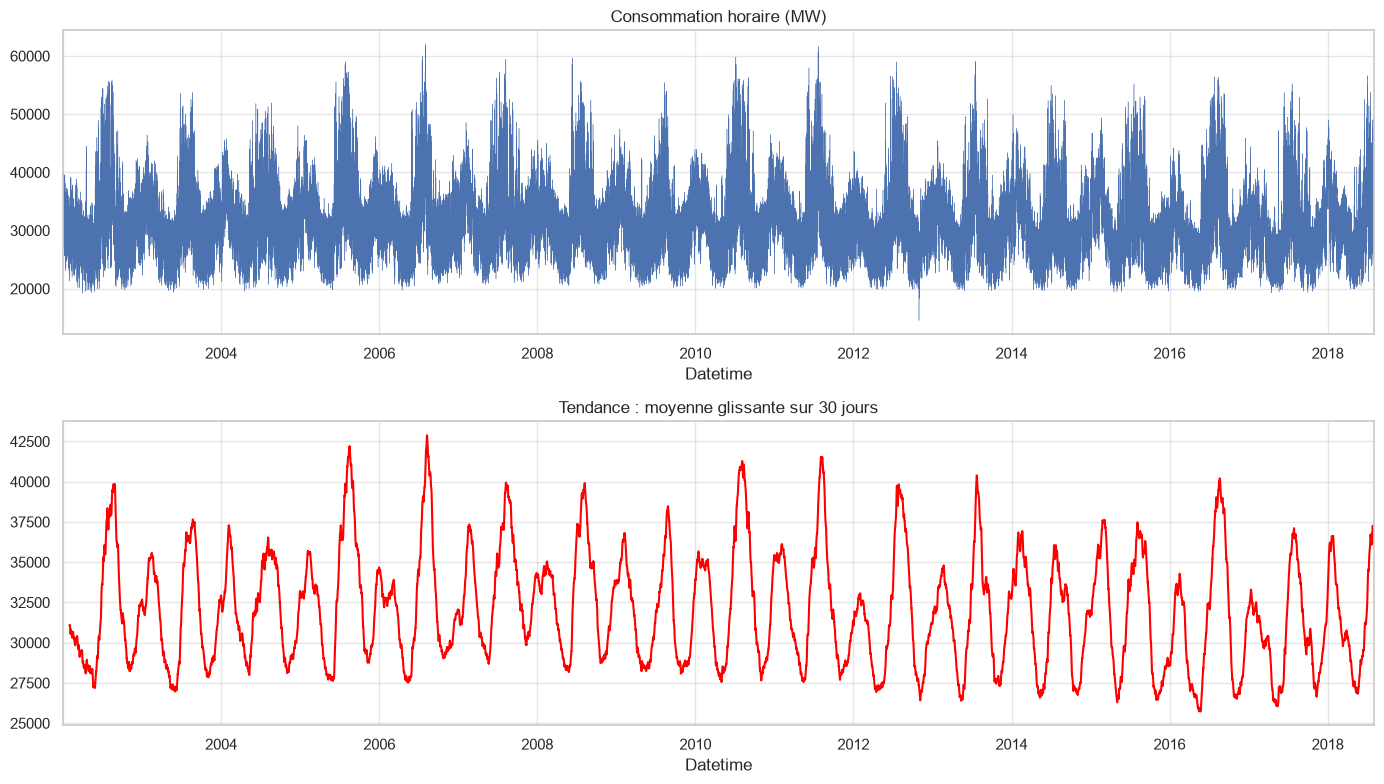

In [19]:
# évolution dans le temps
fig, ax = plt.subplots(2, 1, figsize=(14, 8))

s.plot(ax=ax[0], linewidth=0.3)
ax[0].set_title("Consommation horaire (MW)")

s.rolling(24 * 30).mean().plot(ax=ax[1], color="red")   # moyenne ~30 jours
ax[1].set_title("Tendance : moyenne glissante sur 30 jours")

plt.tight_layout()
plt.show()

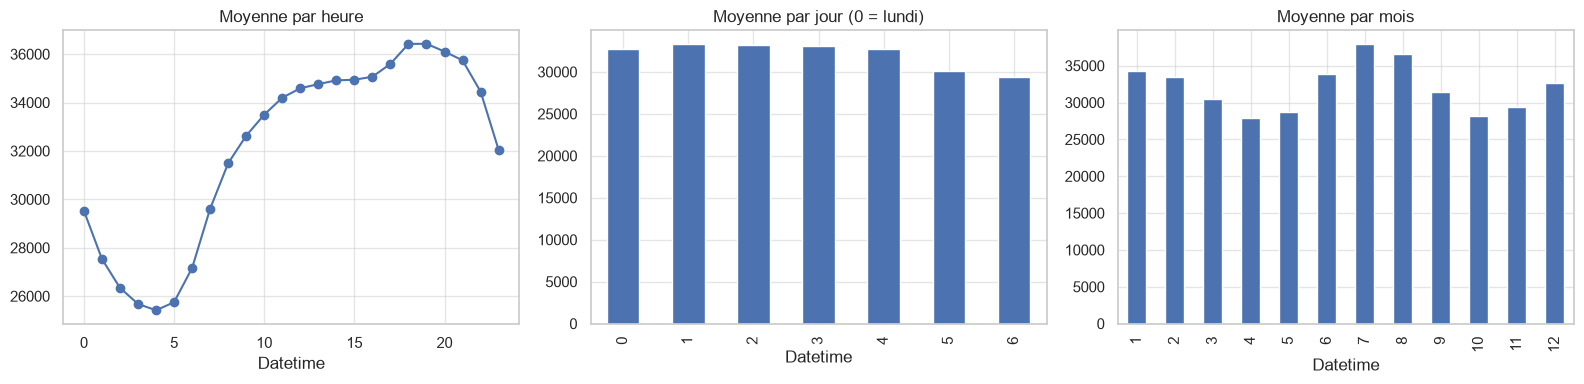

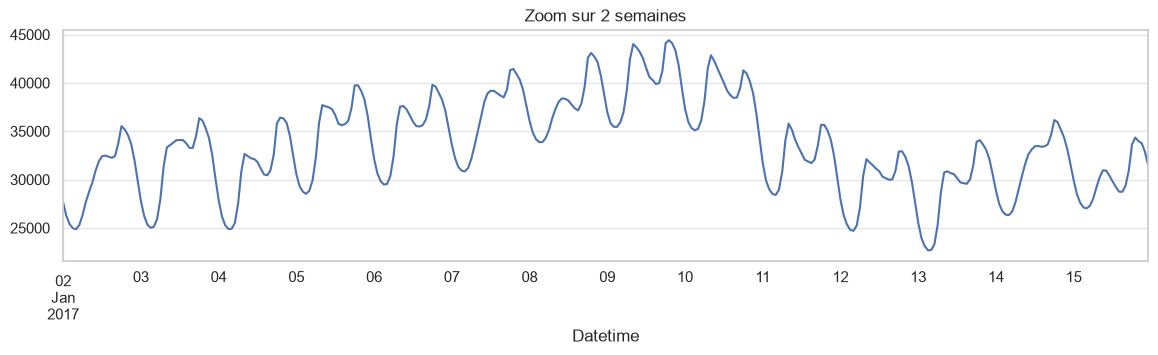

In [21]:
# variations par heure, jour, mois
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

s.groupby(s.index.hour).mean().plot(ax=ax[0], marker="o")
ax[0].set_title("Moyenne par heure")

s.groupby(s.index.day_of_week).mean().plot(ax=ax[1], kind="bar")
ax[1].set_title("Moyenne par jour (0 = lundi)")

s.groupby(s.index.month).mean().plot(ax=ax[2], kind="bar")
ax[2].set_title("Moyenne par mois")

plt.tight_layout()
plt.show()

# Zoom sur 2 semaines pour voir la saisonnalité journalière/hebdomadaire
s["2017-01-02":"2017-01-15"].plot(figsize=(14, 3), title="Zoom sur 2 semaines")
plt.show()

D'après ces représentations ci-dessus je vois:

Cycle journalier : creux la nuit, pics en journée et en soirée.
Cycle hebdomadaire : consommation plus basse le week-end.
Cycle annuel : pics en été (climatisation) et en hiver (chauffage).
Tendance globale à peu près stable.

## Feature Engineering

In [23]:
data = s.to_frame("PJME_MW")


data["Hour"] = data.index.hour
data["DayOfWeek"] = data.index.day_of_week
data["Month"] = data.index.month
data["Year"] = data.index.year
data["IsWeekend"] = (data["DayOfWeek"] >= 5).astype(int)

data["lag24"] = data["PJME_MW"].shift(24)
data["lag168"] = data["PJME_MW"].shift(168)

data["roll_24"] = data["PJME_MW"].shift(1).rolling(24).mean()

data = data.dropna()
data.head()

,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend,lag24,lag168,roll_24
Datetime,,,,,,,,,
2002-01-08 01:00:00,29445.0,1,1,1,2002,0,26862.0,30393.0,33452.583333
2002-01-08 02:00:00,28670.0,2,1,1,2002,0,25976.0,29265.0,33560.208333
2002-01-08 03:00:00,28375.0,3,1,1,2002,0,25641.0,28357.0,33672.458333
2002-01-08 04:00:00,28542.0,4,1,1,2002,0,25666.0,27899.0,33786.375000
2002-01-08 05:00:00,29261.0,5,1,1,2002,0,26328.0,28057.0,33906.208333


## Préparation

In [24]:
target = "PJME_MW"
features = ["Hour", "DayOfWeek", "Month", "Year", "IsWeekend", "lag24", "lag168", "roll_24"]

X = data[features]
y = data[target]

X = pd.get_dummies(X, columns=["Hour", "DayOfWeek", "Month"], drop_first=True, dtype=int)


split = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train :", X_train.index.min(), "->", X_train.index.max())
print("Test  :", X_test.index.min(), "->", X_test.index.max())

Train : 2002-01-08 01:00:00 -> 2015-04-10 19:00:00
Test  : 2015-04-10 20:00:00 -> 2018-08-03 00:00:00


## Modèle, baseline, évaluation

In [25]:
# entraînement et métriques

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

y_base = X_test["lag24"]

def evaluer(y_true, y_hat, nom):
    return {
        "Modèle": nom,
        "MAE": mean_absolute_error(y_true, y_hat),
        "RMSE": root_mean_squared_error(y_true, y_hat),
        "R2": r2_score(y_true, y_hat),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_hat) * 100,
    }

resultats = pd.DataFrame([
    evaluer(y_test, y_base, "Baseline lag24"),
    evaluer(y_test, y_pred, "Régression linéaire"),
]).set_index("Modèle").round(3)
resultats

,MAE,RMSE,R2,MAPE (%)
Modèle,,,,
Baseline lag24,2184.238,3009.006,0.785,6.931
Régression linéaire,1675.914,2240.295,0.881,5.295


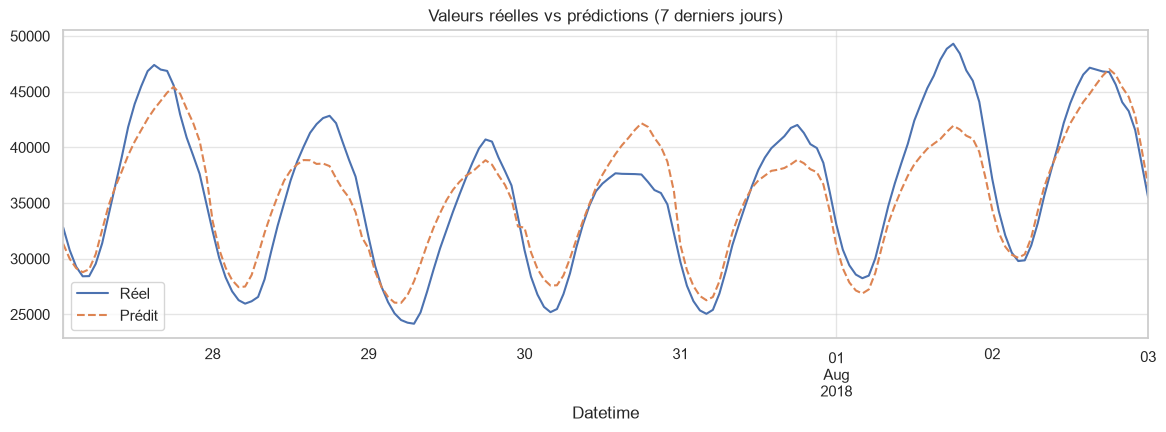

In [26]:
# réel vs prédit
y_pred = pd.Series(y_pred, index=y_test.index)

fig, ax = plt.subplots(figsize=(14, 4))
y_test.iloc[-168:].plot(ax=ax, label="Réel")
y_pred.iloc[-168:].plot(ax=ax, label="Prédit", linestyle="--")
ax.set_title("Valeurs réelles vs prédictions (7 derniers jours)")
ax.legend()
plt.show()

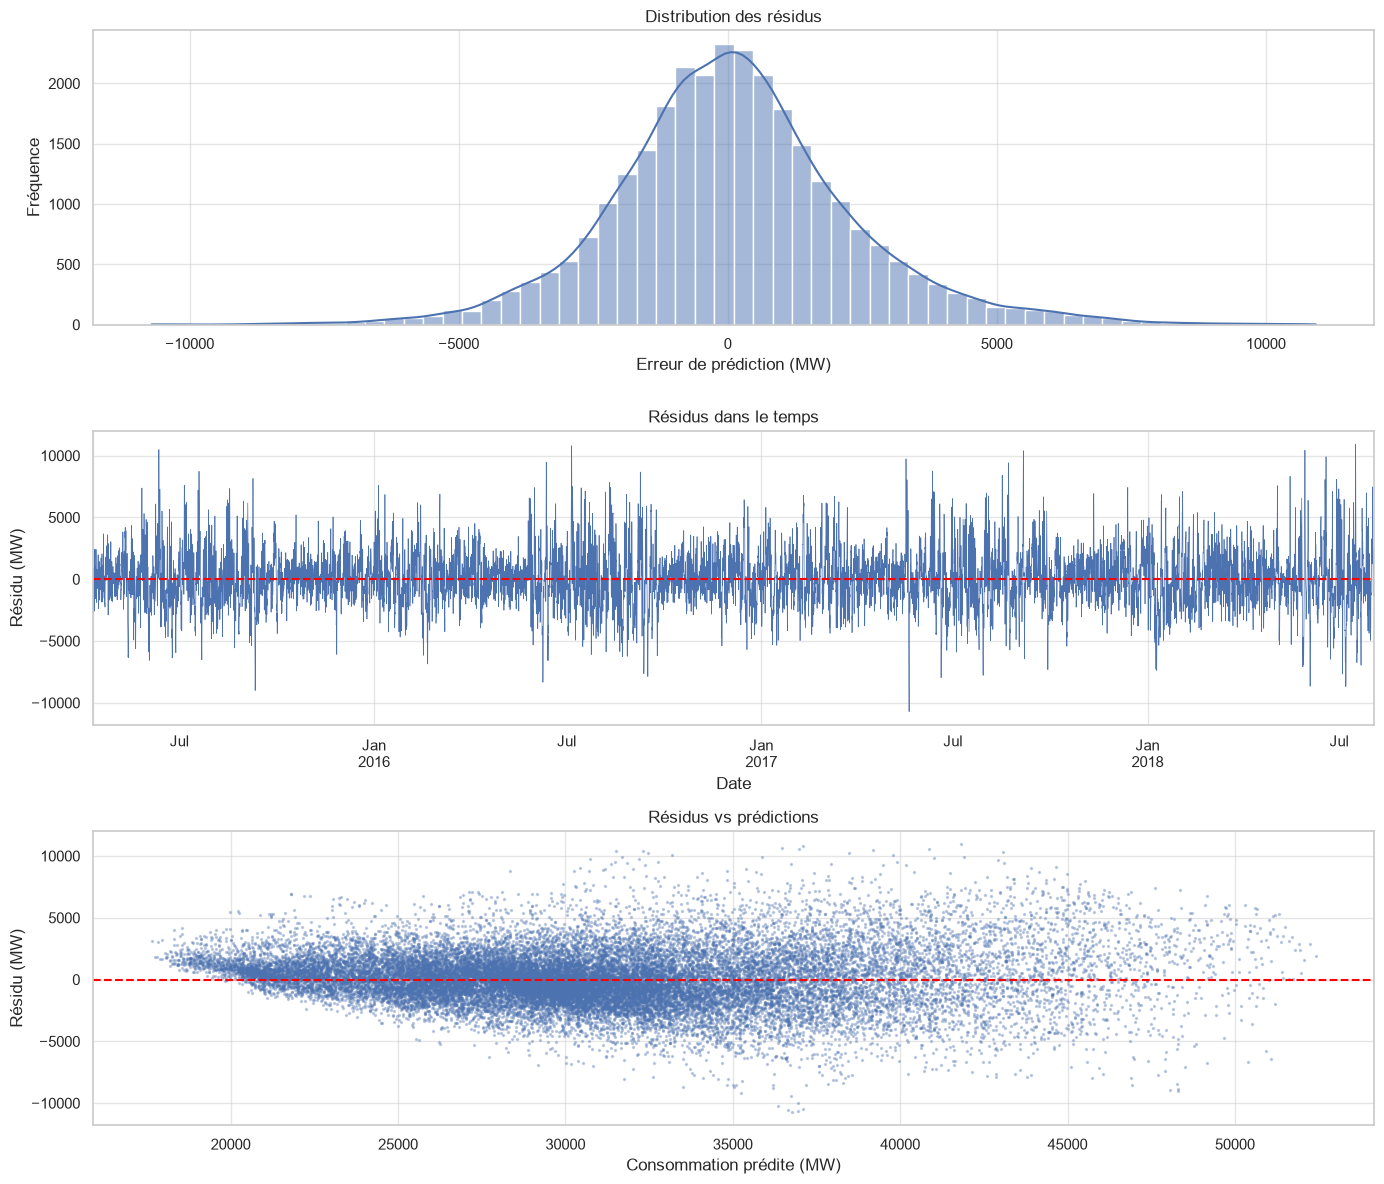

Moyenne des résidus : 96.1 | écart-type : 2238.3


In [29]:
# Analyse des résidus
residus = y_test - y_pred

fig, ax = plt.subplots(3, 1, figsize=(14, 12))

sns.histplot(residus, bins=60, kde=True, ax=ax[0])
ax[0].set_title("Distribution des résidus")
ax[0].set_xlabel("Erreur de prédiction (MW)")
ax[0].set_ylabel("Fréquence")

residus.plot(ax=ax[1], linewidth=0.5)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_title("Résidus dans le temps")
ax[1].set_xlabel("Date")
ax[1].set_ylabel("Résidu (MW)")

ax[2].scatter(y_pred, residus, s=2, alpha=0.3)
ax[2].axhline(0, color="red", linestyle="--")
ax[2].set_title("Résidus vs prédictions")
ax[2].set_xlabel("Consommation prédite (MW)")
ax[2].set_ylabel("Résidu (MW)")

plt.tight_layout()
plt.show()

print("Moyenne des résidus :", residus.mean().round(1),
    "| écart-type :", residus.std().round(1))
